# 02-C语言指针与内存

> 指针保存地址，类型决定怎样访问，长度限定访问范围，生命周期决定地址还能不能用。

这是「嵌入式单片机一套通关」十二篇笔记中的第 02 篇，承接第 01 篇的变量、表达式、流程控制和函数。本篇整理课程中的指针、数组、字符串、复合类型与内存管理，为后续 GPIO、串口缓冲区、传感器数据和图形界面代码打基础。

读完应能回答四个问题：**这块数据在哪里？按什么类型访问？最多能访问多少个元素？谁负责让它一直有效并最终释放？**


## 1. 本篇范围与资料说明

| 课程分组 | 对应小节 | 本篇要解决的问题 |
|---|---|---|
| 5. 指针 | 5.1～5.2 | 取地址、解引用、指针传参、函数指针与回调 |
| 6. 数组 | 6.1～6.4 | 连续存储、数组案例、指针与数组、字符数组与字符串 |
| 7. 复合类型 | 7.1～7.4 | 结构体、联合体、枚举与 typedef |
| 8. 内存管理 | 8.1～8.3 | 常见内存分区、动态分配、对象生命周期 |

**课程来源：**[用户提供的知识库](https://www.yuque.com/embheima/mcu)，当前跳转到[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。本篇已核对目录，并阅读以上 13 个小节可访问的正文；来源索引列在文末。

**整理方式：**沿用课程主题，重新组织解释与案例。代码、练习、自绘图和涉及语言边界的说明为学习补充，不作为课程源码逐字摘录。网页图片与附件未逐一下载复刻。

**示例约定：**使用 C99；使用 `uint8_t`、`uint16_t` 等固定宽度类型时，假定目标工具链提供相应类型。字节布局图明确假定八位字节；实际类型大小、地址与对齐以目标编译器和芯片为准。下文“预期输出”来自代码推导，本次未编译 C 示例或在开发板上运行。标注“代码片段”的内容需要放到合适的函数或源文件中；标注“完整程序”的内容可单独保存为一个 `.c` 文件练习。

建议顺序：先学第 2～8 节理解指针，再学第 9～16 节处理连续数据，最后把复合类型和内存生命周期连起来。


## 2. 对象、地址与指针变量

先从一个普通变量开始：

```c
int value = 25;
int *p = &value;
```

`value` 是一个 `int` 对象，里面存放整数 25；`&value` 取得这个对象的地址；`p` 是一个独立的指针对象，保存这个地址。通过 `*p`，程序访问被指向的 `value`。

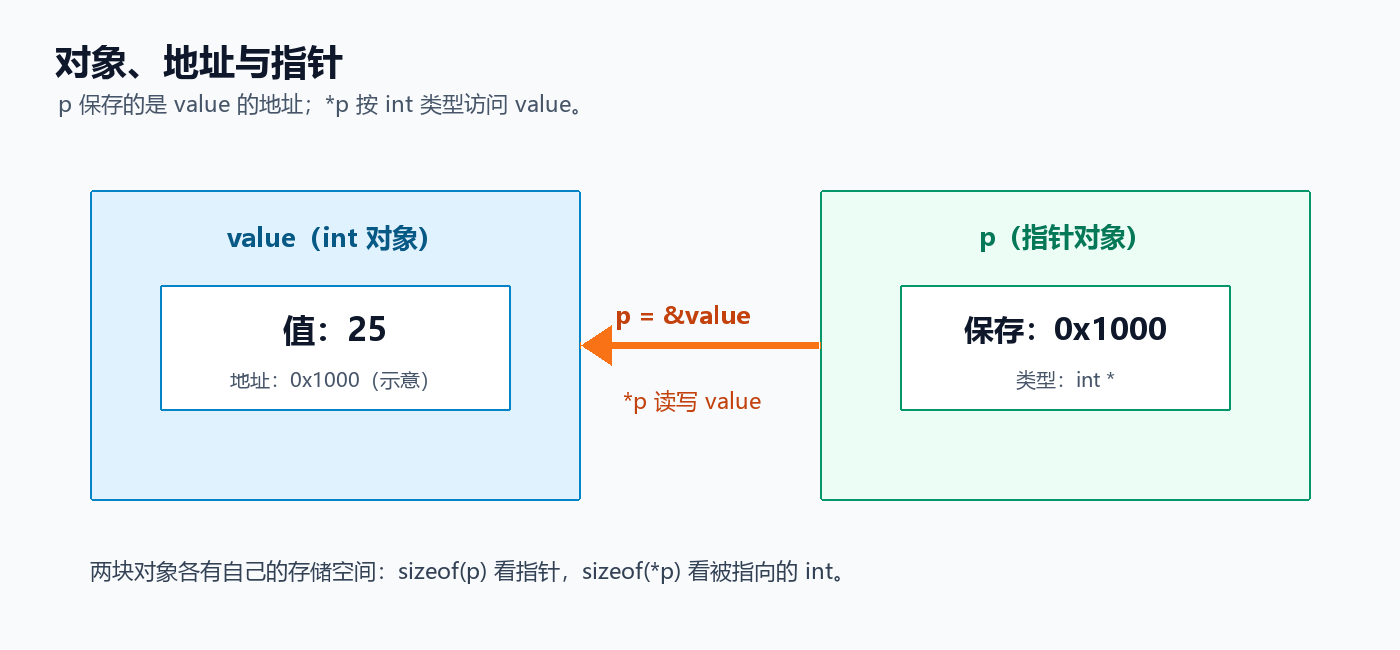

*自绘补充图：地址为教学符号，并非实际运行结果。图中指针对象和整数对象各自占用存储空间。*

| 表达式 | 这里的类型 | 表示什么 |
|---|---|---|
| `value` | `int` | 整数对象的值 |
| `&value` | `int *` | 整数对象的地址 |
| `p` | `int *` | 指针中保存的地址 |
| `*p` | `int` 类型的左值 | 被指向的整数对象，可以读写 |
| `&p` | `int **` | 指针对象自身的地址 |

可以把地址理解为“找到对象的线索”，但不要认为任何看起来像地址的数字都能访问。有效访问还需要正确的类型、对齐、范围和生命周期。

```c
int value = 25;
int *p = &value;

*p = 30;       // 修改 value，预期 value == 30
value = 35;    // 再读 *p，预期为 35
```

两种写法访问同一个对象。指针让函数、数组处理代码和驱动接口能够找到调用者提供的数据。


## 3. 分清声明中的 *、取地址与解引用

| 写法 | 所处位置 | 含义 |
|---|---|---|
| `int *p;` | 声明 | p 是指向 int 的指针 |
| `p = &value;` | 表达式 | 取得 value 的地址并保存 |
| `result = *p;` | 表达式 | 读取 p 指向的对象 |
| `*p = 10;` | 表达式 | 写入 p 指向的对象 |
| `a * b` | 表达式 | 乘法，与解引用是不同用法 |

容易误读的声明：

```c
int *p, value;   // p 是指针，value 是 int
int *q;
int *r;         // 初学时一行声明一个指针，更清楚
```

### sizeof 测量的是哪个对象？

下面是一个完整程序：

```c
#include <stdio.h>

int main(void)
{
    int value = 25;
    int *p = &value;

    printf("value = %d, pointed = %d\n", value, *p);
    printf("value address = %p\n", (void *)&value);
    printf("pointer object address = %p\n", (void *)&p);
    printf("sizeof p = %zu, sizeof *p = %zu\n",
           sizeof p, sizeof *p);
    return 0;
}
```

第一行预期为 `value = 25, pointed = 25`。实际地址和两个大小由实现决定，不给出统一数值。

- `sizeof p`：指针对象本身占多少个 C 字节。
- `sizeof *p`：这里被指向的 `int` 类型占多少个 C 字节；不是获取一整块动态内存的大小。
- `%p` 用于输出对象指针，传参时转换为 `void *`；`size_t` 用 `%zu` 输出。

常见桌面环境中指针可能为 4 或 8 字节，但不能把它作为所有单片机的规则。不同实现、地址空间或指针种类可能使用不同表示；函数指针与对象指针也不保证大小相同。

这里 `sizeof *p` 不会实际读取 `value`，因为 `int` 不是变长类型。不要把这条结论扩大为“所有 sizeof 中的表达式都不会求值”：C99 的变长数组有额外规则。


## 4. 有地址还不够：有效指针与访问边界

访问 `*p` 前，至少确认以下条件：

1. p 已经被赋予有意义的指针值。
2. 指向的对象仍然存在，且访问没有越界。
3. 对齐和访问类型符合要求。
4. 写入时，对象确实允许修改。

| 状态 | 例子或来源 | 能否解引用 |
|---|---|---|
| 指向有效对象 | `int x = 1; int *p = &x;` | 生命周期内、类型正确时可以 |
| 空指针 | `int *p = NULL;` | 不可以 |
| 未初始化指针 | 函数内只写 `int *p;` | 不可以读取并拿来访问 |
| 悬空指针 | 指向已结束生命周期的对象 | 不可以 |
| 数组尾后指针 | 指向最后一个元素之后的位置 | 可用于边界判断，不可解引用 |

下面是安全的空指针检查片段，使用前包含 `<stddef.h>` 或其他定义 `NULL` 的标准头文件：

```c
int value = 8;
int *p = NULL;

p = &value;
if (p != NULL) {
    *p = 9;
}
```

`NULL` 是空指针常量宏；空指针表示“不指向对象”。不要依赖它在内存中一定是全零位，也不要为了构造指针直接填写整数地址。单片机寄存器映射涉及具体工具链和硬件定义，后续外设章节再展开。

**只判断 `p != NULL` 不能证明 p 有效。**已释放的指针、越界指针通常也可能非空。边界和生命周期需要由接口契约、变量作用域和程序逻辑共同保证。

未初始化的普通局部对象具有不确定值，不能当作“可用的随机数”。初始化为 `NULL` 能明确初始状态，但仍需要在解引用前指向有效对象。


## 5. 指针与函数：C 始终按值传递

调用函数时，实参的值被复制给形参。传一个整数，复制整数；传一个指针，复制地址。复制后的指针仍可指向调用者的同一个对象，因此函数能够通过它修改该对象。

下面是一个完整程序：

```c
#include <stdio.h>
#include <stddef.h>

static void change_copy(int value)
{
    value = 99;
    (void)value;
}

static void change_object(int *value)
{
    if (value != NULL) {
        *value = 99;
    }
}

static void swap_int(int *a, int *b)
{
    if (a == NULL || b == NULL) {
        return;
    }
    int temp = *a;
    *a = *b;
    *b = temp;
}

int main(void)
{
    int x = 10;
    int y = 20;

    change_copy(x);
    printf("after copy: %d\n", x);
    change_object(&x);
    printf("after pointer: %d\n", x);
    swap_int(&x, &y);
    printf("after swap: %d %d\n", x, y);
    return 0;
}
```

预期输出：

```text
after copy: 10
after pointer: 99
after swap: 20 99
```

`change_object` 中修改 `*value` 会写入 x；如果只给形参 `value` 重新赋地址，改变的是函数内部的指针副本，不会改变调用者的指针变量。

空指针检查只覆盖空指针输入。这里仍约定非空参数指向活着的、可写的 `int` 对象；函数无法仅凭地址自动验证这一点。


## 6. 输出参数与二级指针

返回值可以表示成功或失败，指针参数可以把结果写回调用者。这种组合在驱动库中很常见。

### 把普通结果写回调用者

以下为函数定义片段，包含 `<stdbool.h>`、`<stddef.h>` 后使用：

```c
bool read_temperature_demo(int *out_c)
{
    if (out_c == NULL) {
        return false;
    }
    *out_c = 26;    // 仅模拟读数
    return true;
}
```

调用片段：

```c
int temperature_c = 0;
if (read_temperature_demo(&temperature_c)) {
    // 成功时，temperature_c 的预期值为 26
}
```

接口应说明失败时输出对象是否保持原值。这个例子在失败时没有写入。

### 要改变调用者的指针变量，就传它的地址

```c
bool select_first(int *data, size_t count, int **out)
{
    if (out == NULL) {
        return false;
    }
    *out = NULL;
    if (data == NULL || count == 0) {
        return false;
    }
    *out = data;
    return true;
}
```

调用片段：

```c
int samples[] = {12, 18, 25};
int *selected = NULL;

if (select_first(samples, 3, &selected)) {
    *selected = 15;  // 修改 samples[0]
}
```

| 层级 | 这里的内容 |
|---|---|
| `out` | selected 这个指针对象的地址，类型为 `int **` |
| `*out` | selected 指针对象，可赋予新的地址 |
| `**out` | selected 指向的 int 对象，前提是各层有效 |

此处返回的是对已有数组的**借用**，没有申请新内存，不应对 selected 调用 `free`。selected 的有效期不能超过 samples 的有效期。

二级指针并不表示“必定是二维数组”。它表示指向指针对象；二维数组的常见类型在第 12 节单独比较。


## 7. const 指针与 void *

### const 限制哪一层？

```c
int a = 10;
int b = 20;

const int *p = &a;         // 不能通过 p 写 a；p 可以改指向
int *const q = &a;         // q 的指向固定；可以通过 q 写 a
const int *const r = &a;   // 指向固定，也不能通过 r 写 a

p = &b;   // 合法
*q = 30;  // 合法
```

| 声明 | 能给指针重新赋地址？ | 能通过它改被指对象？ |
|---|---|---|
| `int *p` | 能 | 能 |
| `const int *p` | 能 | 不能 |
| `int *const p` | 不能 | 能 |
| `const int *const p` | 不能 | 不能 |

`const int *` 约束的是“通过这个访问路径不能修改”。如果原对象是可写的 a，仍能直接写 a。若原对象本身声明为 `const`，强行去掉限定并写入会产生未定义行为。

用于只读输入参数时，写 `const int *data` 能表达接口意图，并让编译器帮助发现误写。它不代表并发访问已经安全。

### void * 能装对象地址，但不知道元素类型

```c
int value = 42;
void *raw = &value;
int *typed = raw;    // C 允许对象指针与 void * 的相应转换
int copy = *typed;   // 预期为 42
```

`void *` 常用于分配器和通用回调上下文。使用前要恢复到正确的对象指针类型；标准 C 不支持直接解引用 `void *` 或对它做元素指针运算。

类型转换不会修复无效地址、错误对齐、越界或生命周期问题。函数指针也不属于这里的通用对象指针规则，不能默认可以放进 `void *` 后再还原。


## 8. 函数指针与回调：把行为传给函数

数据指针指向对象，函数指针指向函数。函数指针的参数和返回类型必须与被调用函数匹配。

```c
int (*operation)(int, int);   // 指针：指向“两个 int 参数，返回 int”的函数
int *operation2(int, int);    // 函数声明：返回 int *，含义不同
```

括号决定声明结合顺序。`int (*operation)(int, int)` 先把 operation 与 `*` 结合，才表示函数指针。

下面是一个完整程序，展示 typedef、回调和上下文指针：

```c
#include <stdio.h>
#include <stddef.h>

typedef void (*SampleCallback)(int value, void *context);

static void deliver_sample(int value,
                           SampleCallback callback,
                           void *context)
{
    if (callback != NULL) {
        callback(value, context);
    }
}

static void print_if_high(int value, void *context)
{
    const int *limit = context;
    if (limit == NULL) {
        return;
    }
    printf("value=%d, high=%d\n", value, value >= *limit);
}

int main(void)
{
    int limit = 35;
    deliver_sample(32, print_if_high, &limit);
    deliver_sample(40, print_if_high, &limit);
    return 0;
}
```

预期输出：

```text
value=32, high=0
value=40, high=1
```

`deliver_sample` 决定何时调用，`print_if_high` 决定收到数据后做什么，`context` 带入本次处理需要的参数。本例回调在函数返回前同步执行，limit 仍然有效。

在异步驱动中，如果把回调和 context 保存下来以后再用，就必须保证 context 对象一直活到回调结束。还要确认回调是在主循环、任务还是中断中执行；中断中的耗时输出、阻塞等待或动态分配，需要遵循平台限制。

不要用强制转换把参数列表不兼容的函数“塞入”回调接口，再通过错误的类型调用。编译器警告通常暴露了真实的接口问题。


## 9. 数组的核心语法：同类型、连续、从零计数

数组是一定数量的同类型元素组成的对象，元素按下标连续排列。

```c
int samples[4] = {10, 20, 30, 40};
int zeros[4] = {0};              // 四个元素都初始化为 0
int partial[4] = {7, 8};         // 预期为 7、8、0、0
int inferred[] = {3, 6, 9};      // 根据初始化器确定为 3 个元素
```

| 对象 | 含义 |
|---|---|
| `samples` | 一个包含 4 个 int 的数组对象 |
| `samples[0]` | 第 1 个元素，值为 10 |
| `samples[3]` | 第 4 个元素，值为 40 |
| `samples[4]` | 越界，不能访问 |

在普通局部作用域中，`int data[4];` 没有初始化；在读取各元素前必须先写入。部分初始化中未显式提供的元素则按规则补零。

```c
size_t count = sizeof samples / sizeof samples[0];
for (size_t i = 0; i < count; ++i) {
    samples[i] += 1;
}
// 预期 samples 为 11、21、31、41
```

这段长度计算需要当前位置的 samples 真的是完整数组，且可使用其大小。传入函数以后，数组参数会调整为指针，不能再用相同公式获得调用者的元素个数。

数组不能通过 `a = b` 整体赋值。可以逐元素复制；在已明确对象大小、允许复制对象表示时，也可使用 `memcpy`，但要注意重叠与边界。结构体的整体赋值是另一条规则。

初学时优先使用编译期固定容量。C99 的变长数组与动态分配不同，支持情况、自动存储消耗和生命周期都需要另外确认。


## 10. 数组案例：最大值与原地反转

把“数据首地址”和“元素个数”同时传给函数。输出参数用来写回最大值；失败返回 false。

下面是一个完整程序：

```c
#include <stdio.h>
#include <stdbool.h>
#include <stddef.h>

static bool array_max(const int *data, size_t count, int *out)
{
    if (data == NULL || out == NULL || count == 0) {
        return false;
    }
    int best = data[0];
    for (size_t i = 1; i < count; ++i) {
        if (data[i] > best) {
            best = data[i];
        }
    }
    *out = best;
    return true;
}

static void reverse_ints(int *data, size_t count)
{
    if (data == NULL || count < 2) {
        return;
    }
    for (size_t i = 0; i < count / 2; ++i) {
        size_t j = count - 1 - i;
        int temp = data[i];
        data[i] = data[j];
        data[j] = temp;
    }
}

int main(void)
{
    int data[] = {-8, -3, -12, -5};
    size_t count = sizeof data / sizeof data[0];
    int best = 0;

    if (!array_max(data, count, &best)) {
        return 1;
    }
    printf("max=%d\n", best);
    reverse_ints(data, count);
    for (size_t i = 0; i < count; ++i) {
        printf("%d%s", data[i], i + 1 == count ? "\n" : " ");
    }
    return 0;
}
```

预期输出：

```text
max=-3
-5 -12 -3 -8
```

最大值从第一个元素开始，而不是写成 0，否则全负数数组会得到错误结果。空数组不具有最大值，因此先检查 count。

反转时每轮交换对称位置，只循环一半。`size_t` 是无符号类型；若直接在 count 为 0 时计算 `count - 1`，会发生回绕。本例先排除小长度，再计算尾部下标。

调用者仍须保证 count 没有超过真实数组长度，out 指向可写且有效的对象。函数收到指针后无法自行查出原始数组容量。


## 11. 数组与指针：相关，但不是同一种对象

```c
int data[4] = {10, 20, 30, 40};
int *p = data;   // 这里 data 转换为指向首元素的指针
```

在大多数表达式中，数组表达式会转换为指向首元素的指针，常称“数组退化”。但数组本身不是“常量指针”：它是保存各元素的对象，没有一个可重新赋地址的数组指针变量。

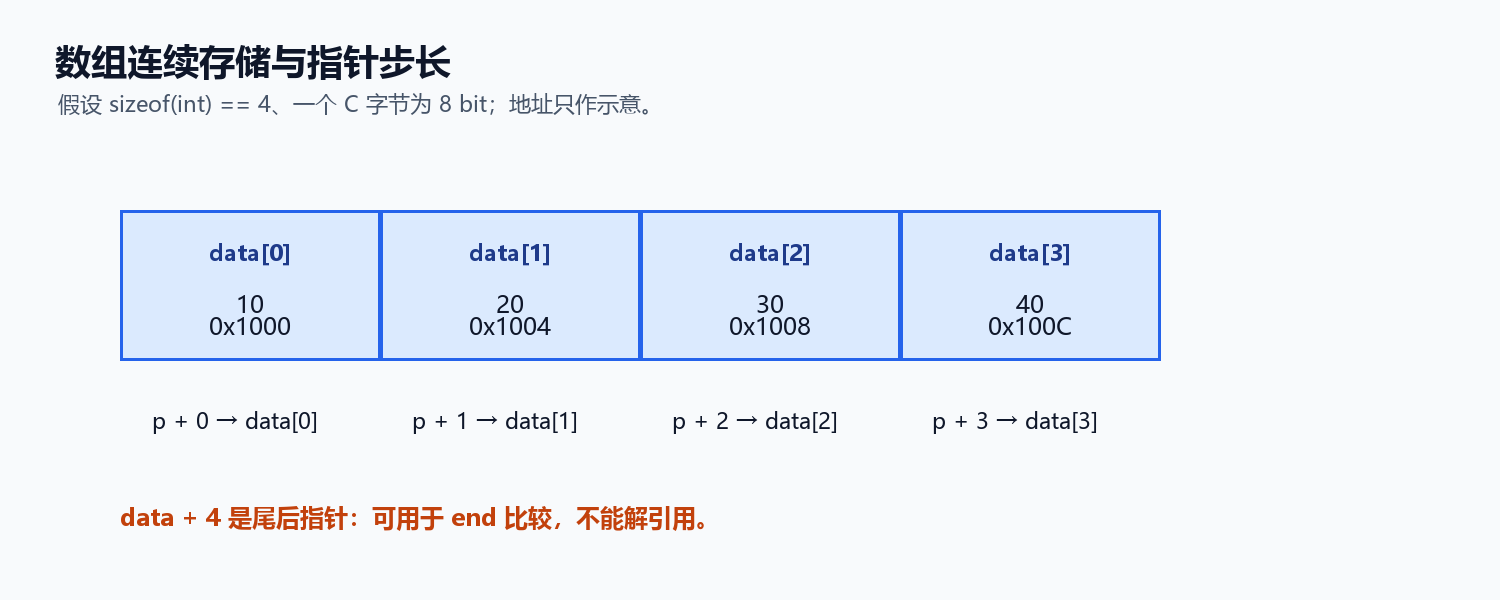

*自绘补充图：假设 `sizeof(int) == 4` 且八位字节，示意相邻元素间隔。此数值只用于图解。*

| 表达式 | 含义 |
|---|---|
| `data[i]` | 第 i 个元素 |
| `*(data + i)` | 在有效范围内，与上式访问同一元素 |
| `p + 1` | 指向下一个 int 元素，跨度是 `sizeof(int)` 个 C 字节 |
| `sizeof data` | 在本作用域中测量整个数组的大小 |
| `sizeof p` | 测量指针对象大小 |
| `&data` | 指向整个数组，类型为 `int (*)[4]` |

数组作为 `sizeof` 或取地址 `&` 的操作数时，不执行通常的首元素指针转换。`data` 转换后的指针与 `&data` 指向的位置起点相同，但类型和步长不同：`data + 1` 走一个元素，`&data + 1` 走整个数组。

### 指针运算的范围

对同一数组，可形成指向各元素和“最后一个元素之后”的指针。尾后指针用于结束判断，不能解引用。

```c
int *begin = data;
int *end = data + 4;      // 尾后位置
for (int *it = begin; it != end; ++it) {
    *it += 1;
}
```

形成更远的越界指针也可能已经违反规则，不能以“我还没读取它”为理由随意越界运算。对同一数组内的指针可以比较顺序或相减；差值按元素个数计算，类型为 `ptrdiff_t`，还要求结果可表示。不把不同独立对象的地址相减来算距离。

`*p++` 按优先级理解为 `*(p++)`：访问旧位置，并移动指针。`(*p)++` 则增加被指向的值。学习阶段用括号和分步语句表达意图，更容易检查边界。


## 12. 指针数组、数组指针与二维数组

| 声明 | 先看哪个部分 | 实际含义 |
|---|---|---|
| `int *p[3];` | p 与 `[3]` 结合 | 3 个 int 指针组成的数组 |
| `int (*p)[3];` | p 与 `*` 结合 | 指向“3 个 int 组成的数组”的指针 |
| `int matrix[2][3];` | 2 个元素，每个也是数组 | 2 行 3 列的二维数组 |
| `int **p;` | 两层 `*` | 指向 int 指针对象的指针 |

### 指针数组保存多个地址

```c
int a = 10;
int b = 20;
int c = 30;
int *items[3] = {&a, &b, &c};

*items[1] = 25;   // 修改 b
```

items 的指针元素连续存储，不代表它们指向的 a、b、c 连续存储。

### 二维数组按行组织

```c
int matrix[2][3] = {
    {1, 2, 3},
    {4, 5, 6}
};
int (*row)[3] = matrix;

int value = row[1][2];      // 预期为 6
int same = *(*(row + 1) + 2);
```

matrix 在这里转换成指向首行的指针，类型为 `int (*)[3]`，不是 `int **`。`row + 1` 跨过一整行，即 `3 * sizeof(int)` 个 C 字节。

接收这种二维数组的函数定义片段：

```c
int sum_matrix(size_t rows, int matrix[][3])
{
    int total = 0;
    for (size_t r = 0; r < rows; ++r) {
        for (size_t c = 0; c < 3; ++c) {
            total += matrix[r][c];
        }
    }
    return total;
}
```

约定 rows 不超过实际行数，传入有效数组，并且总和可由 int 表示；上面的矩阵预期总和为 21。该形参等价于指向三元素行数组的指针，编译器需要列数来确定每行步长。函数实现只读取元素，这里的参数接收前面声明的普通二维数组。

不要把二维数组强制转换为 `int **` 来适配接口。后者会按“读取指针对象”的方式解释行内的整数，类型和对象布局都不匹配。


## 13. 数组函数接口：地址、长度、容量各司其职

```c
void inspect(const int data[], size_t count);
void inspect(const int *data, size_t count);
```

上面两条是同一个参数类型的函数声明；方括号在这里不会把数组整体复制给函数，也不会自动携带长度。写 `int data[10]` 作为普通形参，也不能据此断言调用者一定提供了 10 个元素。

数组处理接口通常明确三类信息：

| 参数 | 意义 | 常见约束 |
|---|---|---|
| 数据指针 | 从哪里开始访问 | 可读或可写、生命周期有效 |
| 长度 length/count | 当前有多少个有效元素 | 不超过实际可访问范围 |
| 容量 capacity | 最多能写多少个元素 | 写入后仍应满足长度 ≤ 容量 |

例如缓冲区追加函数，返回是否成功：

```c
bool append_byte(uint8_t *buffer, size_t capacity,
                 size_t *length, uint8_t value)
{
    if (buffer == NULL || length == NULL || *length >= capacity) {
        return false;
    }
    buffer[*length] = value;
    ++*length;
    return true;
}
```

包含 `<stdint.h>`、`<stddef.h>`、`<stdbool.h>` 后使用。约定 buffer 至少有 capacity 个元素，length 指向单独且已初始化的长度对象。

```c
uint8_t rx[4] = {0};
size_t used = 0;
bool ok1 = append_byte(rx, 4, &used, 0x41);
bool ok2 = append_byte(rx, 4, &used, 0x00);
// 预期两次成功，used == 2；0x00 仍是一个有效数据字节
```

这是二进制缓冲区，used 表示有效数据量。它不需要结尾的零，也不能用 `strlen` 计算数据量。

一个指针只表示访问入口，无法替代这些额外约束。驱动接口中的 `buffer + length`、`size`、`capacity` 不是多余参数。


## 14. 字符数组与字符串：结束符是关键

C 字符串是一段以 `\0` 结束的字符序列。字符数组只有在可访问范围内存在结束符时，才能按字符串使用。

```c
char text[] = "MCU";                  // 4 个 char：M、C、U、\0
char same[] = {'M', 'C', 'U', '\0'};   // 同样是字符串
char raw[] = {'M', 'C', 'U'};          // 3 个 char，没有结束符
char buffer[8] = "MCU";               // 容量 8，当前字符串长度 3
```

| 表达式 | 上面例子的结果 | 统计什么 |
|---|---:|---|
| `sizeof text` | 4 | 整个数组大小，含结束符 |
| `strlen(text)` | 3 | 结束符之前的 char 个数 |
| `sizeof buffer` | 8 | 数组容量 |
| `strlen(buffer)` | 3 | 当前字符串长度 |

使用 `strlen` 需要 `<string.h>`，并提前保证参数指向有效的、以零终止的字符串。对 raw 调用 `strlen` 或用 `%s` 输出会越过合法范围寻找结束符。

`'\0'` 是值为零的字符，`'0'` 是数字字符，二者不同。字符串中若出现内嵌零，字符串函数在第一个零处停止。

### 字符串字面量与可写数组

```c
const char *label = "MCU";   // 指向字面量，按只读使用
char editable[] = "MCU";    // 自己的可写数组副本

editable[0] = 'm';          // 合法，预期为 "mCU"
```

C 语法可能允许 `char *p = "MCU";`，但字面量不可修改；写 `p[0] = 'm'` 是未定义行为。采用 `const char *` 能更早暴露误写。

`strlen` 统计 char 单元，不保证等于人眼看到的文字个数。比如在八位字节的 UTF-8 环境中，一个中文字符常占多个字节；屏幕排版的字符计数是另一个问题。


## 15. 字符串输入输出与常用库函数

### 先按容量约束输入

以下为完整程序；它保留 `fgets` 获取的行，包含输入中的换行符（如果读到了）。

```c
#include <stdio.h>

int main(void)
{
    char line[16];
    if (fgets(line, sizeof line, stdin) == NULL) {
        return 1;
    }
    printf("read: %s", line);
    return 0;
}
```

成功时，`fgets` 最多写入容量减一的字符并补 `\0`。它可能保留换行，也可能因为容量不足只读入一行的前半部分；剩余输入要由调用者按业务处理。

若练习 `scanf`，必须约束 `%s` 的宽度：

```c
char word[16];
if (scanf("%15s", word) == 1) {
    printf("%s\n", word);
}
```

`%15s` 最多读取 15 个非空白字符，给结束符留一个位置；它不会读取带空格的整行。传入 word 即可，不写 `&word` 来替代预期的首字符指针。

### 库函数需要哪些前提？

| 函数 | 功能 | 使用前必须明确 |
|---|---|---|
| `strlen(s)` | 长度，不含结尾零 | s 在合法范围内以零结束 |
| `strcpy(dst, src)` | 复制，包含结尾零 | dst 容量 ≥ `strlen(src)+1`，不重叠 |
| `strcat(dst, src)` | 追加到 dst 的结尾 | 两者已终止，剩余容量足够，不重叠 |
| `strcmp(a, b)` | 按字符序列比较 | 都是有效字符串；判断结果的符号 |
| `snprintf(dst, cap, ...)` | 有界格式化 | 容量正确，检查失败或截断 |
| `memcpy(dst, src, n)` | 复制 n 个字节 | 两段范围有效且不重叠，不自动补零 |
| `memmove(dst, src, n)` | 复制，允许重叠 | 两段范围均有效，不自动补零 |

`strcmp` 相等返回 0；小于返回负值，大于返回正值，不保证只返回 -1 或 1。比较字符串内容不能用 `a == b`，后者比较指针值。

`strncpy` 若源长度达到限制，可能不补零，不能把它当作“自动安全的 strcpy”。`sprintf` 没有目的缓冲区容量参数；格式化到固定数组时优先考虑 `snprintf`。

```c
char label[16];
int written = snprintf(label, sizeof label, "ADC=%u", 2048U);
if (written < 0) {
    // 格式化失败
} else if ((size_t)written >= sizeof label) {
    // 需要的长度超出容量，发生截断
} else {
    // 成功，预期字符串为 "ADC=2048"
}
```

这里只讨论标准接口语义。嵌入式工具链的精简 C 库、浮点格式化选项及输出重定向，需结合工程设置确认。


## 16. 手写长度与有界复制：把前提放进接口

课程用自定义 `strlen` 训练指针遍历。先看核心思想：

```c
size_t text_length(const char *text)
{
    const char *p = text;
    while (*p != '\0') {
        ++p;
    }
    return (size_t)(p - text);
}
```

这段函数定义要求 text 是有效的零终止字符串，且指针差值可由 `ptrdiff_t` 表示。它不具备容量检查能力；不能把未经验证的串口数据直接传入。

处理已知容量的字符数组时，可以先检查结束符是否在范围内：

```c
bool text_length_bounded(const char *text, size_t capacity,
                         size_t *out_length)
{
    if (text == NULL || out_length == NULL) {
        return false;
    }
    for (size_t i = 0; i < capacity; ++i) {
        if (text[i] == '\0') {
            *out_length = i;
            return true;
        }
    }
    return false;
}
```

容量检查成立的前提，仍是 text 确实能读取 capacity 个 char。容量参数不是操作系统替你查出的大小，而是调用者给出的契约。

下面是带源容量和目的容量的复制函数定义片段。包含 `<stdbool.h>`、`<stddef.h>`、`<string.h>` 后使用，并放在上面的有界长度函数之后。两段缓冲区须分别能访问其容量指定的范围；长度函数的输出参数应指向独立且可写的 size_t 对象：

```c
bool copy_text(char *destination, size_t destination_capacity,
               const char *source, size_t source_capacity)
{
    size_t length = 0;
    if (destination == NULL || source == NULL ||
        destination_capacity == 0) {
        return false;
    }
    if (!text_length_bounded(source, source_capacity, &length)) {
        return false;
    }
    if (length >= destination_capacity) {
        return false;          // 给结尾零留出空间
    }
    memmove(destination, source, length + 1);
    return true;
}
```

它在失败时保持目的缓冲区原值；成功时复制包含结束符的 `length + 1` 个 char，并允许两段存储重叠。

```c
char source[] = "GD32";
char target[8] = "old";
bool ok = copy_text(target, sizeof target, source, sizeof source);
// 预期 ok 为 true，target 为 "GD32"
```

这种接口把“不越界读取源”和“不越界写入目的”分开检查。实际项目可以使用经过验证的库实现，不必重复造每个字符串函数。


## 17. 结构体：把一组相关数据放在一起

数组适合同类型数据，结构体适合把一个对象的不同属性组合起来。

以下是声明与使用片段：

```c
#include <stdint.h>
#include <stdbool.h>

typedef struct {
    uint16_t raw;
    int temperature_c;
    bool valid;
} SensorReading;

SensorReading reading = {
    .raw = 2048,
    .temperature_c = 26,
    .valid = true
};

SensorReading *p = &reading;
reading.temperature_c = 27;
p->valid = false;
```

| 写法 | 用途 | 等价关系 |
|---|---|---|
| `reading.raw` | 用结构体对象访问成员 | 直接成员访问 |
| `p->raw` | 用结构体指针访问成员 | 等价于 `(*p).raw` |
| `SensorReading copy = reading;` | 整体复制结构体值 | 各成员值被复制 |

`p->raw` 前仍须保证 p 有效。把结构体传入函数时，同样遵守按值传递：

```c
void mark_copy(SensorReading reading)
{
    reading.valid = true;
    (void)reading;
}

void mark_original(SensorReading *reading)
{
    if (reading != NULL) {
        reading->valid = true;
    }
}
```

只读查看可用 `const SensorReading *`，修改原对象可用 `SensorReading *`。是否值得避免复制，取决于对象大小和接口需求，不能笼统说所有结构体都必须用指针传参。

**结构体中的数组成员会随整体赋值复制；指针成员只复制地址。**如果成员指向动态内存，两个结构体副本可能指向同一块数据。这是浅复制，需要另行设计所有权，不能让两份副本分别 free 同一地址。


## 18. 对齐与填充：sizeof 不一定等于成员大小之和

编译器会按目标 ABI 的对齐规则安排成员，成员之间或结构体末尾可能留出填充字节。

```c
typedef struct {
    uint8_t status;
    uint32_t ticks;
    uint16_t raw;
} PacketFields;
```

若假定八位字节，并且上述三个类型的大小与对齐分别为 1、4、2，一个常见布局为：

| 字节偏移 | 内容 |
|---|---|
| 0 | status |
| 1～3 | 为 ticks 对齐而填充 |
| 4～7 | ticks |
| 8～9 | raw |
| 10～11 | 为结构体数组中的下一个元素对齐而填充 |

该假设下 `sizeof(PacketFields)` 为 12，成员大小之和只有 7。换目标、编译器选项或声明，结果可能不同，不能把 12 作为 C 标准保证。

可用下面的完整程序观察本机实现，输出数字以实际结果为准：

```c
#include <stdio.h>
#include <stddef.h>
#include <stdint.h>

typedef struct {
    uint8_t status;
    uint32_t ticks;
    uint16_t raw;
} PacketFields;

int main(void)
{
    printf("size=%zu\n", sizeof(PacketFields));
    printf("status=%zu, ticks=%zu, raw=%zu\n",
           offsetof(PacketFields, status),
           offsetof(PacketFields, ticks),
           offsetof(PacketFields, raw));
    return 0;
}
```

### 结构体不自动等于通信帧

串口、I2C/SPI 设备或文件格式通常规定明确的字节顺序、长度和字段偏移。直接把整个结构体发送出去可能混入填充，还会受整数宽度和端序影响；`memcmp` 整个结构体也不一定等价于比较成员值。

对一个规定为“大端、16 位、两个八位字节”的字段，可明确编码：

```c
uint16_t value = 0x1234U;
uint8_t frame[2];
frame[0] = (uint8_t)(value >> 8);
frame[1] = (uint8_t)(value & 0xFFU);
// 预期为 0x12、0x34

uint16_t decoded = (uint16_t)(((uint32_t)frame[0] << 8) |
                               (uint32_t)frame[1]);
// 预期 decoded == 0x1234
```

这里固定宽度类型与八位字节是协议示例的前提。不要通过把字节缓冲区强制转换为结构体指针来省掉解析步骤；这还可能遇到对齐和类型访问规则问题。


## 19. 共用体（联合体）：共享空间，配上类型标记

结构体的成员分别占有空间；联合体的成员共享起始存储区。同一时刻通常把其中一个成员作为当前有效值来使用。

```c
typedef union {
    int count;
    float voltage;
} Value;
```

`sizeof(Value)` 至少足够容纳最大成员，还可能为对齐增加大小，不保证严格等于最大成员大小。

```c
Value value;
value.count = 10;
value.voltage = 3.3f;  // 改为存电压，原来的 count 不再作为当前值使用
```

不要把 `value.voltage` 写入后读 `value.count` 当作一般数值转换。某些联合体位模式重解释写法依赖表示和实现条件，还可能得到陷阱表示；入门代码直接读取当前有效成员。

### 用枚举记录当前成员

```c
typedef enum {
    VALUE_COUNT,
    VALUE_VOLTAGE
} ValueKind;

typedef struct {
    ValueKind kind;
    Value value;
} TaggedValue;

TaggedValue result = {
    .kind = VALUE_COUNT,
    .value = {.count = 12}
};

if (result.kind == VALUE_COUNT) {
    int count = result.value.count;
    (void)count;
}
```

kind 和 union 成员必须一起维护。只改 kind 而不写对应成员，或只写成员而忘记改 kind，都会破坏接口约定。

联合体适合“一个消息可能包含多种负载，但每次只用一种”的情况。节省空间的收益与读写复杂度需要一起考虑。


## 20. 枚举与 typedef：给状态和类型命名

### 枚举让状态有名字

```c
typedef enum {
    DEVICE_IDLE = 0,
    DEVICE_SAMPLING,      // 预期值 1
    DEVICE_ERROR = 10,
    DEVICE_RECOVERING     // 预期值 11
} DeviceState;

DeviceState state = DEVICE_IDLE;
```

没有显式赋值时，第一个枚举常量从 0 开始，其后接前一个值加一。C99 中枚举常量具有 int 类型；枚举对象的兼容整数类型及实际大小由实现选择，不能默认是固定一字节。

枚举表达了合法状态集合，但不会自动提供运行时校验。外部数据仍需检查：

```c
bool decode_state(unsigned int raw, DeviceState *out)
{
    if (out == NULL) {
        return false;
    }
    switch (raw) {
    case 0:  *out = DEVICE_IDLE;       return true;
    case 1:  *out = DEVICE_SAMPLING;   return true;
    case 10: *out = DEVICE_ERROR;      return true;
    case 11: *out = DEVICE_RECOVERING; return true;
    default: return false;
    }
}
```

收到串口字节后不能仅强制转换成枚举就视为验证成功。需要固定的协议宽度时，先用明确宽度的整数字段编解码，再映射为枚举状态。

### typedef 是类型别名

```c
typedef unsigned int Counter;
typedef struct Sensor Sensor;
typedef void (*EventCallback)(int event);
```

typedef 让声明更可读，没有自动创造一个与原类型互不兼容的全新类型。和 `#define` 的文本替换不同，typedef 按语言的类型规则解释。

指针别名会隐藏一层含义：

```c
typedef int *IntPtr;
int value = 1;
const IntPtr p = &value;   // 实际是 int *const，p 的指向固定
*p = 2;                   // 仍能改 value
```

它不是 `const int *`。初学和接口设计时，优先保留直观的指针声明，不为了缩短名字而隐藏读写权限。


## 21. 作用域、生命周期与所有权

作用域回答“哪里能使用这个名字”，生命周期回答“这个对象什么时候存在”，所有权回答“谁负责管理资源”。三者要分开判断。

| 对象来源 | 名字通常在哪里可见 | 对象通常存在多久 | 常见管理方式 |
|---|---|---|---|
| 普通块内局部对象 | 所在块内 | 进入该块到离开该块 | 自动存储，无需 free |
| 函数形参 | 函数体内 | 本次函数调用 | 自动存储 |
| 块内 static 对象 | 所在块内 | 整个程序执行期间 | 静态存储，无需 free |
| 文件作用域对象 | 受声明与链接规则约束 | 整个程序执行期间 | 静态存储 |
| malloc 得到的存储 | 通过保存的指针访问 | 成功分配到释放之间 | 由约定的拥有者释放 |
| 字符串字面量 | 通过表达式或指针使用 | 整个程序执行期间 | 不修改，不 free |

这里描述的是 C 的对象存储期与生命周期。自动对象在实际机器上常放在栈或寄存器，优化后也可能不对应一块独立内存；语言规则并不要求每个局部变量都物理放在栈上。

### 拥有与借用

- **拥有者**负责释放动态资源，释放次数恰好一次。
- **借用者**可以按接口许可访问数据，但不负责释放。
- **只读借用**常用 `const T *` 表达，仍要约定长度与有效期。

这些是程序设计约定，C 编译器不会完整替你追踪。给函数命名、写接口注释、减少别名和集中清理，能让约定更容易执行。

如果把指针保存到全局对象、结构体、任务队列或回调中，就把使用时间延长了。此时尤其要检查它指向的数据是否在后续使用前已经失效。


## 22. 常见内存分区：用作模型，不当作固定地图

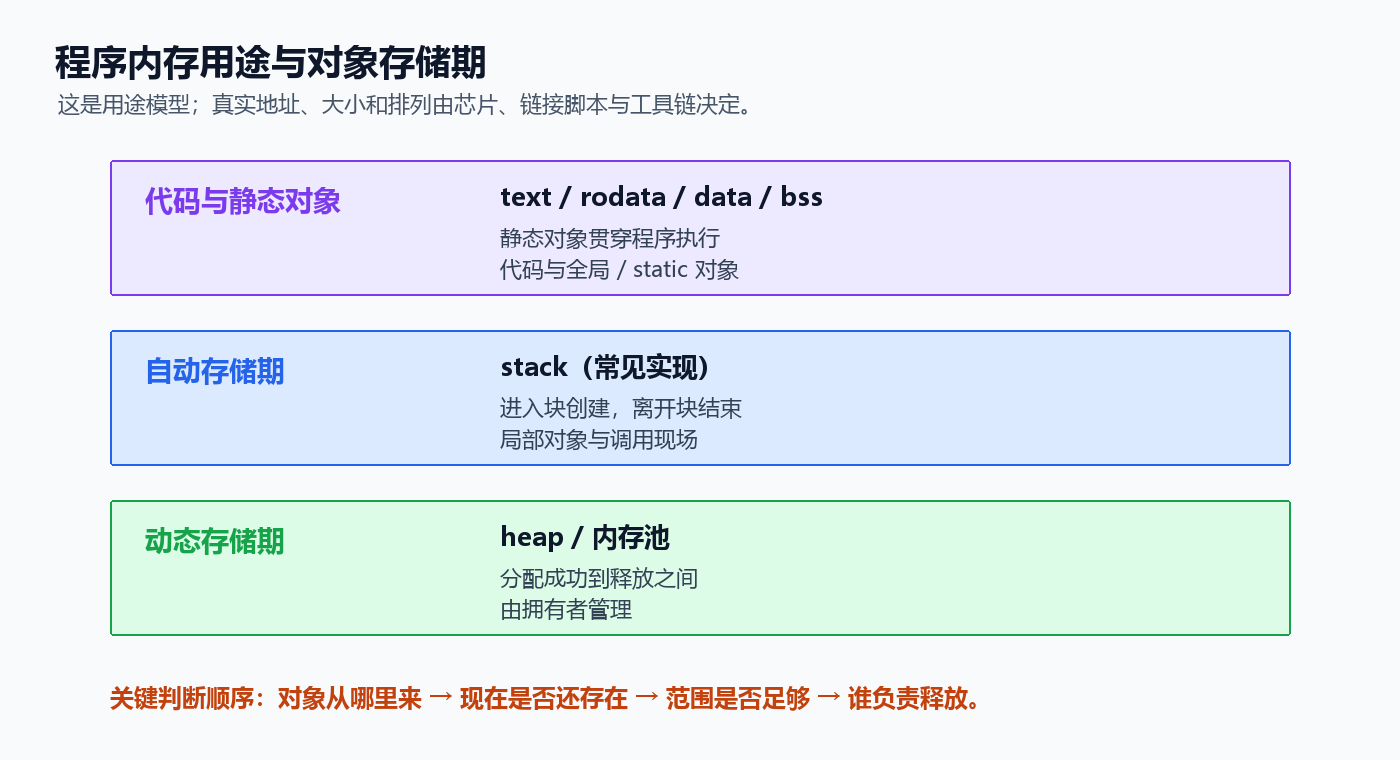

*自绘补充图：按用途分类，未表示真实地址次序、大小或增长方向。具体布局看目标芯片、链接脚本、启动代码和工具链。*

| 常见名称 | 常见内容 | 需要注意 |
|---|---|---|
| `.text` | 可执行指令 | 单片机中常位于 Flash，位置由链接决定 |
| `.rodata` | 常量、字符串等只读数据 | 是工具链常见区段，不是 C 强制的物理区域 |
| `.data` | 带非零等初始化值的可写静态对象 | MCU 中常有 Flash 中的初值副本和 RAM 中的运行对象 |
| `.bss` | 零初始化或未显式初始化的静态对象 | 启动过程按规则建立初始值，常见实现会清零 |
| heap / 堆 | 分配器管理的动态存储 | 可不启用；容量和策略由工程决定 |
| stack / 栈 | 调用现场、部分自动对象等 | 大数组、递归、深层调用可能增加占用 |

`int global;` 若在文件作用域，是按规则零初始化；函数内部的普通 `int local;` 不是。不要根据变量有没有写 `= 0`，就把所有“未初始化变量”归为同一类。

预处理、编译、汇编、链接决定代码与区段如何形成；程序启动时还要完成数据初始化。典型 MCU 启动代码从 Flash 复制 `.data` 初值到 RAM，并为 `.bss` 建立零初值，然后进入应用。精确流程以实际工程为准。

### 从桌面例子迁移到单片机

桌面操作系统通常有虚拟内存和成熟运行库；裸机 MCU 可能只有有限 Flash/RAM，且需要自己配置栈、堆和输出接口。不能假定堆一定比栈大，或者堆和栈总是按某个固定方向相向增长。

RTOS 的每个任务常有独立栈，任务栈与 C 库 malloc 管理的堆不一定由同一分配器负责。后续操作系统或工程配置中，需要分别看任务栈、动态分配池和链接映射。

判断内存占用时，查看 map 文件、链接配置和运行时测量。仅凭某个变量写了 const、static 或 malloc，不能推导完整的物理地址布局。


## 23. 返回地址时，先问对象还活着吗？

### 错误示例：返回普通局部数组地址

下面是**反例，不要用于程序**：

```c
int *bad_buffer(void)
{
    int data[3] = {1, 2, 3};
    return data;  // 返回后 data 生命周期结束，结果悬空
}
```

即使调试时偶尔能读出旧值，也不代表对象仍然存在。后续调用可能复用存储，编译器也可以基于语言规则进行优化；不能依赖这种现象。

### 方案一：调用者提供缓冲区

```c
bool fill_three(int *out, size_t capacity)
{
    if (out == NULL || capacity < 3) {
        return false;
    }
    out[0] = 1;
    out[1] = 2;
    out[2] = 3;
    return true;
}
```

调用者决定对象存在哪里、多久有效。对于固定长度外设数据，这种接口通常很直观。

### 方案二：返回静态对象地址

```c
const int *fixed_three(void)
{
    static const int data[3] = {1, 2, 3};
    return data;
}
```

data 一直存在，地址可以继续用；不允许修改或 free。可写 static 缓冲区则会被多次调用共享，可能覆盖旧结果，也需要考虑并发与重入。

### 方案三：返回动态分配对象

可以返回 malloc 得到的地址，但必须检查失败，并明确把释放责任交给调用者。返回地址本身不延长普通局部对象的生命周期，malloc 的生命周期来自分配器规则。

### static 局部变量的状态保持

```c
unsigned int next_sequence(void)
{
    static unsigned int sequence = 0;
    return ++sequence;
}
```

最初三次调用预期返回 1、2、3。C 中该对象具有静态存储期，初始化在程序启动前完成，之后可以被程序修改。不是“每次调用都重新初始化”，也不是“第一次调用后值不可变”。无符号计数到达最大值后会按模规则回绕；多线程或中断并发需要额外协调。


## 24. 动态内存：申请、初始化、使用、释放

包含 `<stdlib.h>` 后可使用标准分配接口：

| 接口 | 主要语义 | 常见误解 |
|---|---|---|
| `malloc(size)` | 成功时返回至少 size 字节的存储，失败返回空指针 | 新存储里的内容没有自动初始化 |
| `calloc(count, size)` | 为多个对象申请存储并置零位 | 全零位不等于任意类型的有效“零值”表示 |
| `realloc(ptr, size)` | 调整已分配块的大小，可能移动 | 失败时原块仍在，不能丢失原指针 |
| `free(ptr)` | 释放相应分配器返回的块 | 不能释放局部数组、静态对象或内部偏移地址 |

本篇用 malloc 后按元素赋值，避免在初始化之前读取。C 中 malloc 返回的 `void *` 可转换为对象指针，不需要写强制转换；必须包含正确头文件。

```c
int *data = malloc(count * sizeof *data);
```

`sizeof *data` 与声明类型保持一致，类型改变时不容易漏改。但这行之前仍须检查 count 合法以及乘法不会溢出。

### 调整大小时保留旧指针

以下是片段，约定 old 是可交给 realloc 的块，new_count 非零且已检查 `new_count * sizeof *old` 不溢出：

```c
int *temporary = realloc(old, new_count * sizeof *old);
if (temporary != NULL) {
    old = temporary;
    // 若容量增大，新增元素还需要初始化
} else {
    // old 仍指向原有块，按原容量继续处理或释放
}
```

不要直接写 `old = realloc(old, ...)` 后才检查失败，否则失败时原地址可能丢失。成功后原块指针及其别名失效，应统一改用返回的新指针。

为简化跨实现行为，本篇主动排除零大小申请和 `realloc(ptr, 0)`。零大小调用存在特殊规则，不用它们承载普通业务逻辑。

标准分配器提供普通对象所需的适当对齐；DMA 的特殊对齐、总线可访问 RAM、缓存维护等条件，需要由具体平台接口满足，不能仅凭 malloc 成功就确定。


## 25. 动态数组完整示例：先查数量，再分配

课程 8.2 用输入数量后申请整型数组的案例介绍 malloc/free。下面改写为确定数量的练习，补上数量、乘法溢出、申请失败和初始化检查；不把终端输入处理混入这个示例。

这是一个完整程序：

```c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <stddef.h>

int main(void)
{
    const size_t count = 6;
    int *data = NULL;

    if (count == 0 || count > SIZE_MAX / sizeof *data) {
        fprintf(stderr, "invalid count\n");
        return 1;
    }
    data = malloc(count * sizeof *data);
    if (data == NULL) {
        fprintf(stderr, "allocation failed\n");
        return 1;
    }

    for (size_t i = 0; i < count; ++i) {
        data[i] = (int)i;  // 本例 i 为 0～5，转换可表示
    }
    for (size_t i = 0; i < count; ++i) {
        printf("%d%s", data[i], i + 1 == count ? "\n" : " ");
    }

    free(data);
    data = NULL;
    return 0;
}
```

申请成功时的预期输出：

```text
0 1 2 3 4 5
```

关键检查：

1. count 不为 0；实际业务还应设置合理上限。
2. 先判断 `count > SIZE_MAX / sizeof *data`，避免乘法已溢出后才检查。
3. malloc 失败立即退出，不解引用空指针。
4. 每个元素先写入，再读取。
5. 拥有者在所有使用结束后释放一次。

若以后把 count 改为外部输入，不仅要验证可分配容量，还要重新检查 `(int)i` 的可表示范围，或改用匹配的数据类型。不能把本例的有限数量前提直接去掉。

### free 的边界

`free(NULL)` 可以调用且无效果。对于非空地址，只能释放当前仍由对应分配器管理的基地址；`free(data + 1)`、重复 free、释放普通数组都不合法。

```c
int *alias = data;  // 假设此刻 data 指向已申请的块
free(data);
data = NULL;
// alias 也已失效，不能再读取 *alias 或 free(alias)
```

上面是独立的生命周期示意片段，不能接在完整程序的 free 后再次执行。把 data 置空只改变一个指针变量，不会自动更新所有别名。

在多个分配步骤的函数中，任何失败路径都要释放已经拥有的资源。可以集中到统一清理出口，但不要为了写清理语句而重复释放同一块。


## 26. 单片机里的内存选择与缓冲区交接

| 选择 | 适合情况 | 代价与约束 |
|---|---|---|
| 局部固定数组 | 小型、短期计算 | 增加当前调用或任务栈压力，不能返回后继续使用 |
| static / 全局固定数组 | 容量已知、需要长期存在 | 长期占 RAM；共享访问要协调 |
| 调用者提供缓冲区 | 驱动或算法接口 | 调用者负责容量和生命周期 |
| malloc / RTOS 分配器 | 运行时大小变化，工程支持动态内存 | 可能失败、碎片、时间波动，需要明确释放责任 |
| 固定块内存池 | 固定规格消息、强调可预测性 | 需要管理池容量、分配和归还规则 |

固定缓冲区在 MCU 中很常用，但容量越大越占 RAM。动态内存也不是一概不能用：是否使用取决于系统实时性、运行时长、分配策略和工程要求。

### 异步发送时的数据不能提前失效

假设驱动只保存发送指针，稍后通过中断或 DMA 读取：

```c
// 示意接口，不是可直接调用的硬件库
bool uart_send_async(const uint8_t *data, size_t length);
```

调用后立刻离开保存局部数组的作用域，或立刻修改/释放数据，都可能破坏传输。应读接口说明，确认数据是“立即复制到内部缓存”还是“借用到发送完成”。

一个常见生命周期约定是：

```text
准备缓冲区 → 提交发送 → 驱动读取期间保持有效且稳定
          → 收到完成通知 → 才允许复用或释放
```

同样的原则适用于任务队列、回调上下文和 LVGL 对象引用：**保存了指针，就需要保存它背后的有效对象。**

`volatile` 用于特定可观察访问要求，不能修复越界或悬空指针，也不自动提供原子性、互斥或完整的跨任务同步。共享缓冲区要按平台的中断、RTOS 和缓存规则设计。


## 27. 综合示例：用结构体组织采样缓冲区

把固定数组、字符串、结构体、枚举、只读指针和回调放在一起。这个程序处理模拟 ADC 原始数据，不访问真实硬件。

设计约定：名称容量为 8；采样容量为 4；ADC 原始值有效范围为 0～4095；失败时不提交结果。统计结果的 sum 使用 `uint32_t`，四个最大值之和 16380 可以表示。

这是一个完整程序：

```c
#include <stdio.h>
#include <stdint.h>
#include <stddef.h>
#include <stdbool.h>
#include <inttypes.h>

#define SAMPLE_CAPACITY 4U
#define ADC_MAX_VALUE 4095U

typedef enum {
    SENSOR_IDLE,
    SENSOR_READY,
    SENSOR_ERROR
} SensorState;

typedef struct {
    char name[8];
    uint16_t samples[SAMPLE_CAPACITY];
    size_t count;
    SensorState state;
} SensorBuffer;

typedef struct {
    uint16_t minimum;
    uint16_t maximum;
    uint32_t sum;
} SampleStats;

typedef void (*StatsCallback)(const SensorBuffer *sensor,
                              const SampleStats *stats);

static bool append_sample(SensorBuffer *sensor, uint16_t value)
{
    if (sensor == NULL) {
        return false;
    }
    if (sensor->count >= SAMPLE_CAPACITY || value > ADC_MAX_VALUE) {
        sensor->state = SENSOR_ERROR;
        return false;
    }
    sensor->samples[sensor->count] = value;
    ++sensor->count;
    sensor->state = SENSOR_READY;
    return true;
}

static bool calculate_stats(const SensorBuffer *sensor,
                             SampleStats *out)
{
    if (sensor == NULL || out == NULL ||
        sensor->state != SENSOR_READY || sensor->count == 0 ||
        sensor->count > SAMPLE_CAPACITY) {
        return false;
    }

    SampleStats stats = {
        .minimum = sensor->samples[0],
        .maximum = sensor->samples[0],
        .sum = 0
    };
    for (size_t i = 0; i < sensor->count; ++i) {
        uint16_t value = sensor->samples[i];
        if (value > ADC_MAX_VALUE) {
            return false;
        }
        if (value < stats.minimum) {
            stats.minimum = value;
        }
        if (value > stats.maximum) {
            stats.maximum = value;
        }
        stats.sum += value;
    }
    *out = stats;
    return true;
}

static void print_stats(const SensorBuffer *sensor,
                         const SampleStats *stats)
{
    // 本例调用者保证两个指针有效，name 已正确零终止
    printf("%s: count=%zu min=%u max=%u sum=%" PRIu32 "\n",
           sensor->name, sensor->count,
           (unsigned int)stats->minimum,
           (unsigned int)stats->maximum,
           stats->sum);
}

static bool report_sensor(const SensorBuffer *sensor,
                           StatsCallback callback)
{
    SampleStats stats;
    if (callback == NULL || !calculate_stats(sensor, &stats)) {
        return false;
    }
    callback(sensor, &stats); // 同步借用，回调返回后不再使用 stats
    return true;
}

int main(void)
{
    SensorBuffer sensor = {
        .name = "ADC0",
        .samples = {0},
        .count = 0,
        .state = SENSOR_IDLE
    };
    const uint16_t input[] = {1000, 1200, 800, 1600};
    const size_t input_count = sizeof input / sizeof input[0];

    for (size_t i = 0; i < input_count; ++i) {
        if (!append_sample(&sensor, input[i])) {
            fprintf(stderr, "sample rejected\n");
            return 1;
        }
    }
    if (!report_sensor(&sensor, print_stats)) {
        fprintf(stderr, "report failed\n");
        return 1;
    }
    return 0;
}
```

预期输出：

```text
ADC0: count=4 min=800 max=1600 sum=4600
```

| 知识点 | 在程序中的落点 |
|---|---|
| 固定数组 | samples 的真实容量由结构体声明决定 |
| 长度 | count 只统计已写入的有效样本 |
| 字符串 | name 初始化包含结束符，输出用 `%s` |
| 结构体指针 | append_sample 修改原对象，calculate_stats 只读借用 |
| 输出参数 | 统计成功后才用 `*out = stats` 提交结果 |
| 枚举 | state 记录准备与错误状态 |
| 回调 | report_sensor 把输出行为交给调用者 |
| 生命周期 | 回调同步使用局部 stats，不保存其地址 |

练习第五次追加时，本例会返回 false、保持 count 为 4 并把状态设为 ERROR。随后 report_sensor 也会失败；这是明确的错误策略。若业务要“丢弃新样本但仍显示旧数据”，应一起修改状态规则和调用者处理方式。

print_stats 在此是本程序内部的回调，依赖 name 的初始化约定；若将其升级为接受任意外部对象的通用接口，还应验证名称是否在容量内结束。


## 28. 常见错误与排查顺序

| 现象或写法 | 原因 | 优先检查 |
|---|---|---|
| 声明 `int *p;` 后直接写 `*p` | 没有指向有效对象 | 初始化与赋地址位置 |
| p 非空但访问崩溃 | 越界、悬空、对齐或类型错误 | 对象来源、范围和有效期 |
| 交换函数执行后原变量没变 | 只交换形参副本 | 是否传地址并修改 `*p` |
| 函数内 `sizeof(data)` 求长度 | 数组形参已调整为指针 | 明确传 count/capacity |
| `i <= count` 访问数组 | 访问了尾后位置 | 有效下标为 0～count-1 |
| 用 `int **` 接二维数组 | 行数组布局与指针对象布局不同 | 数组指针类型和列数 |
| `%s` 输出乱码或越界 | 无结束符、缓冲区无效 | 容量内是否有 `\0` |
| 两个内容相同的字符串比较不等 | 用了指针相等比较 | 改用 strcmp 并检查符号 |
| 改字符串字面量 | 字面量不可写 | 使用可写字符数组 |
| 返回局部数组地址 | 返回后对象已失效 | 调用者缓冲区或其他生命周期方案 |
| malloc 后立即读数据 | 未初始化分配的存储 | 写入后再读取 |
| `malloc(n * sizeof(T))` 空间异常 | 数量或乘法溢出 | 业务上限与 SIZE_MAX 检查 |
| free 后另一指针仍使用 | 别名也已经悬空 | 统一所有权，结束全部借用 |
| 直接发送结构体结果不一致 | 填充、宽度、端序差异 | 逐字段协议编码 |
| 异步发送内容偶尔改变 | 提前改写或复用缓冲区 | 完成通知与缓冲区使用期限 |

排查指针问题时，按下面的顺序更容易定位：

```text
对象从哪里来？ → 现在是否还存在？ → 长度/容量是否正确？
→ 指针类型和对齐是否正确？ → 谁在修改或释放它？
```

编译器警告是第一道线索，尤其关注不兼容指针、返回局部地址、格式串不匹配和数组越界。若在支持的桌面工具链中练习，可使用 AddressSanitizer 等工具寻找越界和释放后访问；工具能覆盖的范围仍取决于测试路径。

本篇未执行这些 C 检测工具。遇到未定义行为的反例，也不应以“跑出某个数字”作为正确性证据。


## 29. 自测与动手练习

先写出判断和理由，再与下一节对照。不要运行故意越界或悬空的片段来猜结果。

### 自测

1. `int x = 5; int *p = &x; *p = 8;` 后 x、`*p` 各是多少？`&p` 的类型是什么？
2. `int *p, q;` 中 q 是指针吗？
3. 在声明 `int a[5]; int *p = a;` 的同一作用域中，`sizeof a`、`sizeof p` 分别测量什么？
4. 对 `int a[5]`，`a + 5` 能形成吗？能访问 `*(a + 5)` 吗？
5. `const int *p` 和 `int *const p` 各限制什么？
6. 传参 `change(p)`，若 change 内部只重新赋值形参 p，会改变调用者的 p 吗？要修改调用者的指针变量，需传什么？
7. `char a[] = "ABC"; char b[8] = "ABC";` 的容量和字符串长度分别是多少？
8. `char a[3] = {'A','B','C'};` 能直接交给 strlen 吗？
9. `strcmp(a,b)` 大于零时，能断言结果是 1 吗？
10. `int matrix[2][3]` 转换后的首行指针类型是什么？
11. 结构体整体赋值会复制数组成员吗？指针成员指向的数据会自动深复制吗？
12. free 后把一个指针设为 NULL，其他别名会自动变成 NULL 吗？
13. 普通局部数组、static 局部数组、malloc 块，哪个可以在创建函数返回后继续存在？有哪些条件？
14. `calloc` 的零位初始化是否保证任意指针类型得到空指针值？

### 动手练习

1. 给第 10 节数组最大值函数加一个最小值输出。用全负数、单元素、空长度三个情况检查设计。
2. 用第 13 节 append_byte 向容量为 4 的缓冲区追加 5 个字节。记录每次返回值与 used，失败后不能写入尾后位置。
3. 用第 16 节 copy_text 复制 `"ABC"`，分别给目的容量 4 和 3。确认失败是否保留原数据。
4. 给联合体消息增加“电压”与“计数”两个分支的输出，并对未知 kind 做拒绝处理。
5. 把第 27 节输入改为 `{0, 4095, 4095, 0}`，推导输出；再尝试第五次追加，解释状态变化。
6. 写一个接收调用者缓冲区的 `fill_three` 调用，说明哪个对象负责提供存储，为什么不用 free。

练习完成标准不是“没崩溃”，而是能写清每次访问的范围、对象有效期和失败后的状态。


## 30. 自测参考答案与练习检查点

| 题号 | 参考答案 |
|---|---|
| 1 | x 和 `*p` 都为 8；`&p` 为 `int **` |
| 2 | q 是 int，只有 p 是指针 |
| 3 | `sizeof a` 为 `5 * sizeof(int)`，`sizeof p` 为指针对象大小 |
| 4 | 可以形成尾后指针；不能解引用 |
| 5 | 前者不能通过 p 改对象，但可改指向；后者不能改指向，但可改对象 |
| 6 | 不会；应传 p 自身的地址并用匹配的二级指针接收，或返回新指针再由调用者赋值 |
| 7 | a 容量 4、b 容量 8；字符串长度都是 3 |
| 8 | 不能，数组内没有结束符 |
| 9 | 不能，只保证结果为正 |
| 10 | `int (*)[3]`，不是 `int **` |
| 11 | 数组成员值随结构体复制；指针只复制地址，不自动深复制 |
| 12 | 不会，别名依旧失效，不能继续访问或释放 |
| 13 | static 数组在程序期间存在；malloc 块到 free 前存在；普通局部数组离开作用域后失效 |
| 14 | 不保证，零位模式与各种类型的零值表示需要区分 |

动手练习检查点：

- 最大/最小值均应从第一个有效元素出发，count 为 0 时返回失败，不访问 data[0]。
- append_byte 前四次成功，used 依次为 1、2、3、4；第五次失败，used 保持 4。
- `"ABC"` 需要 4 个 char；目的容量 4 成功，容量 3 失败且保持原内容。
- 联合体只读取 kind 对应成员，未知 kind 不随意选择成员。
- 输入 `{0,4095,4095,0}` 时预期：count=4、min=0、max=4095、sum=8190；第五次追加按本例策略进入 ERROR。
- 调用者创建普通数组后将地址和容量交给 fill_three；该数组不是动态分配块，不调用 free。

扩展思考：如果回调把第 27 节 stats 的地址保存起来，函数返回后还能用吗？不能。需要把结果复制到自己的有效对象中，或重新设计存储与所有权。


## 31. 一页复习与十二篇学习路线

| 主题 | 记住这条规则 |
|---|---|
| 指针 | 地址、类型、范围、生命周期一起决定能否访问 |
| 解引用 | `*p` 访问被指对象，`&p` 取得指针对象自身地址 |
| 传参 | C 按值传递；复制地址后可间接修改原对象 |
| const | 区分不能改指向与不能通过指针改数据 |
| 函数指针 | 签名必须匹配；回调上下文必须活到使用结束 |
| 数组 | 连续元素，从零计数；尾后位置不能读取 |
| 数组退化 | 大多数表达式转首元素指针，sizeof 和 & 等情形不同 |
| 缓冲区 | 区分有效长度和真实容量，函数参数不能自动恢复容量 |
| 字符串 | 容量中留一个结束符位置，二进制数据使用显式长度 |
| 结构体 | 值复制不等于指针成员的深复制，布局不等于协议格式 |
| 联合体 | 共享存储，与类型标记一起维护 |
| 生命周期 | 地址可被保存，不代表对象寿命会延长 |
| 动态分配 | 检查数量与失败，先初始化，拥有者释放一次 |
| MCU 内存 | 看工程实际布局与使用期限，异步操作完成后再复用缓冲区 |

十二篇规划保持如下：

| 编号 | 笔记主题 | 学习衔接 |
|---|---|---|
| 01 | C语言核心语法与函数 | 变量、表达式、流程控制、函数与多文件 |
| **02** | **C语言指针与内存（本篇）** | **数组、字符串、复合类型、生命周期与分配** |
| 03 | 单片机入门与开发环境 | 芯片认识、工程搭建、编译下载和调试 |
| 04 | GPIO与基础外设控制 | 引脚输入输出与基础外设应用 |
| 05 | 中断与定时器 | 事件响应、计时与周期任务 |
| 06 | 串口、DMA与通信模块 | 数据收发、传输缓冲区与异步交接 |
| 07 | 实时时钟与系统管理 | 时间与系统功能 |
| 08 | I2C与SPI通信 | 总线与外设数据交互 |
| 09 | ADC与传感器采集 | 模拟量、采样与数据处理 |
| 10 | 存储器与文件系统 | 数据持久化与文件操作 |
| 11 | 屏幕显示与触摸驱动 | 显示刷新与触摸输入 |
| 12 | LVGL图形界面开发 | 图形对象、事件和应用整合 |

第 03 篇会开始把这里的 C 语言知识放进实际单片机工程；看到驱动函数里的指针参数时，先确认它接受的是对象、数组、长度还是回调。


## 32. 课程来源索引

核对日期：2026-10-11。以下链接是本篇主题对应的课程原文入口；本文解释、代码与图示为重新整理的配套学习内容。

| 分组 | 已核对的课程小节 |
|---|---|
| 指针 | [5.1 指针核心语法](https://www.yuque.com/xxcls/mcu/ir9edlweqf6a26hb)、[5.2 指针和函数](https://www.yuque.com/xxcls/mcu/gy6h8qr415zdbwgf) |
| 数组 | [6.1 数组的核心语法](https://www.yuque.com/xxcls/mcu/gplx4nitl6qm51oo)、[6.2 数组案例](https://www.yuque.com/xxcls/mcu/rq28fk3naqau5e48)、[6.3 数组和指针](https://www.yuque.com/xxcls/mcu/dua0alny10zuvnxk)、[6.4 字符数组与字符串](https://www.yuque.com/xxcls/mcu/vd4c3a56i5z9r130) |
| 复合类型 | [7.1 结构体](https://www.yuque.com/xxcls/mcu/bbvcyp3863zgppxp)、[7.2 共用体（联合体）](https://www.yuque.com/xxcls/mcu/gne294p5ndd1mxgx)、[7.3 枚举](https://www.yuque.com/xxcls/mcu/xr0g0wip8gcdwinh)、[7.4 typedef](https://www.yuque.com/xxcls/mcu/og1e8zaugfqbs6y8) |
| 内存管理 | [8.1 内存分布](https://www.yuque.com/xxcls/mcu/zoqke9xbuqi1m4yo)、[8.2 堆区内存的使用](https://www.yuque.com/xxcls/mcu/gmol69zi1eavfn08)、[8.3 内存分布代码分析](https://www.yuque.com/xxcls/mcu/aopa8lpc7zwetagv) |

阅读范围为上述页面可访问的正文和目录，未逐一下载页面图片及附件。图中地址、内存分区排列、对齐算例均已注明假设，不能替代目标芯片手册和工具链文档。

本文代码统一为 C99 学习示例，未进行本地 C 编译、运行或开发板验证。预期输出与练习答案为人工推导，并在交付时检查了关键算例与笔记文件结构。
